# Step 7 — Error Analysis

**Purpose.** Step 6 fixed the final model (ensemble, NDCG@10 0.4201). This step asks *where and why* it succeeds or fails, to support the final report:

1. How ranking quality is distributed across slates (how often the model gets a slate completely wrong).
2. Performance by segment: cold vs warm items, user recency, history length, slate length, query length, promotion dependence, and the strongest interaction in the slate.
3. What distinguishes failed slates from successful ones.
4. Where the neural model and LightGBM disagree, and who wins.
5. Worked examples of a personal-history success, a cold-item success, and a failure.

**Inputs:** `step6_test_predictions.parquet` (Step 6), plus `features.parquet`, `events.parquet`, `users.parquet` and the product metadata (category IDs only). Only columns available after Step 3 are used, so the notebook runs on any version of the feature table.
**Runtime:** ~10 min on a Colab CPU runtime (no GPU needed).

In [1]:
import os, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa, pyarrow.csv as pacsv, pyarrow.dataset as ds

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/JDSearch/Raw Data')
except ImportError:
    DATA_DIR = Path(os.environ.get('JD_DATA_DIR', '~/Downloads/JDsearch')).expanduser()
OUT_DIR = DATA_DIR / 'processed'
PRED_PATH = Path(os.environ.get('JD_PRED', OUT_DIR / 'step6_test_predictions.parquet'))
SFX = '_smoke' if 'JD_PRED' in os.environ else ''
TEST_DATE, ORD = pd.Timestamp('2022-10-17'), 2
MODELS = {'ensemble': 'ensemble', 'neural': 'neural', 'LightGBM': 'lgbm'}

pred = pd.read_parquet(PRED_PATH)
COLS = ['uc_days_since_any', 'i_users_cart_90d', 'q_name_tfidf_sim', 'u_days_since_click', 'slate_len', 'q_n_terms']
f = ds.dataset(OUT_DIR / 'features.parquet').to_table(columns=['user', 'wid'] + COLS,
                                                       filter=ds.field('split') == 'test').to_pandas()
df = pred.merge(f, on=['user', 'wid'], how='left', validate='one_to_one')
df = df.sort_values('user', kind='stable').reset_index(drop=True)
del f; gc.collect()
users = pd.read_parquet(OUT_DIR / 'users.parquet', columns=['user', 'n_hist']).set_index('user')['n_hist']
print(f'{len(df):,} test candidates in {df["user"].nunique():,} slates')

Mounted at /content/drive
2,306,388 test candidates in 25,822 slates


## Candidate-level context

- **cold**: the product appears in no user's history (no personal or popularity signal can exist for it).
- **personal**: this user has interacted with this exact product before (inside the retention windows).
- **pop_pct / text_pct**: the candidate's percentile *within its slate* for cart popularity and query–name text match (1 = best in slate).
- **promotion lift**: how festival-driven the candidate's level-3 category is (Step 4c), from the order calendar.

In [2]:
hist_wids = np.unique(pd.read_parquet(OUT_DIR / 'events.parquet', columns=['wid'])['wid'].to_numpy())
w = df['wid'].to_numpy(); j = np.searchsorted(hist_wids, w)
df['cold'] = (j >= len(hist_wids)) | (hist_wids[np.minimum(j, len(hist_wids) - 1)] != w)
df['personal'] = df['uc_days_since_any'].notna()
g = df.groupby('user')
df['pop_pct'] = g['i_users_cart_90d'].rank(pct=True)
df['text_pct'] = g['q_name_tfidf_sim'].rank(pct=True)
for name, col in MODELS.items():
    df[f'rank_{name}'] = g[col].rank(ascending=False, method='first').astype(int)

# promotion dependence of each candidate's category (same definition as Step 4c)
prod = pacsv.read_csv(DATA_DIR / 'product_meta_data.txt',
    parse_options=pacsv.ParseOptions(delimiter='\t', quote_char=False),
    convert_options=pacsv.ConvertOptions(include_columns=['wid', 'cate_id_3'],
                                         column_types={'wid': pa.int64(), 'cate_id_3': pa.int64()})).to_pandas()
cat3 = prod.set_index('wid')['cate_id_3']
del prod; gc.collect()
o = pd.read_parquet(OUT_DIR / 'events.parquet', columns=['wid', 'type', 'age_days'])
o = o[o['type'] == ORD]
o['cat3'] = cat3.reindex(o['wid']).to_numpy()
o = o.dropna(subset=['cat3'])
date = TEST_DATE - pd.to_timedelta(np.floor(o['age_days']), unit='D')
fest = np.zeros(len(o), bool)
for s, e in [('2021-11-01', '2021-11-11'), ('2021-12-10', '2021-12-12'), ('2022-06-01', '2022-06-18')]:
    fest |= ((date >= s) & (date <= e)).to_numpy()
p = fest.mean()
gc3 = pd.DataFrame({'c': o['cat3'].to_numpy(), 'f': fest}).groupby('c')['f'].agg(['sum', 'size'])
lift = np.log(((gc3['sum'] + 50 * p) / (gc3['size'] + 50)) / p)
df['promo_lift'] = lift.reindex(cat3.reindex(df['wid']).to_numpy()).to_numpy()
del o, date, fest, cat3; gc.collect()
print(f"cold candidates {df['cold'].mean():.1%} | with personal history {df['personal'].mean():.1%} | "
      f"promotion lift available {df['promo_lift'].notna().mean():.1%}")

cold candidates 56.7% | with personal history 0.8% | promotion lift available 99.4%


## 1. How ranking quality is distributed

Per-slate NDCG@10 for the final ensemble (same definition as every earlier step, random tie-breaking). A slate with NDCG@10 = 0 is a **complete miss**: no interacted item made the top 10.

complete miss (NDCG@10 = 0)        27.6%
partial (0 < NDCG@10 < 1)          55.0%
perfect (NDCG@10 = 1)              17.4%
first interacted item at #1        28.0%
first interacted item in top 3     48.8%
first interacted item in top 10    72.4%


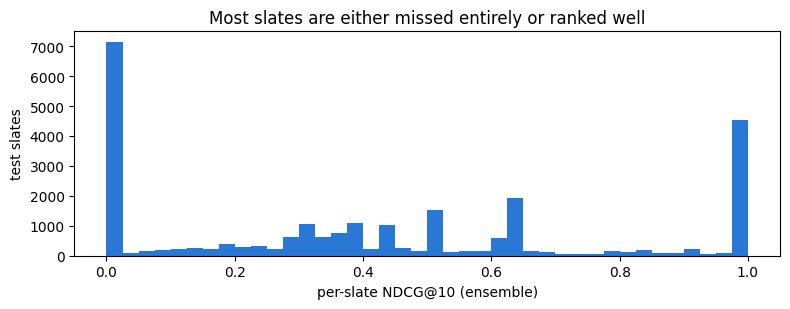

In [3]:
def slate_metrics(u, lab, score, k=10, seed=0):
    lab = lab.astype(np.float64)
    r = np.random.default_rng(seed).random(len(u))
    order = np.lexsort((r, -np.asarray(score, dtype=np.float64), u))
    u_s, lab_s = u[order], lab[order]
    start = np.r_[0, np.flatnonzero(u_s[1:] != u_s[:-1]) + 1]
    size = np.diff(np.r_[start, len(u_s)])
    rank = np.arange(len(u_s)) - np.repeat(start, size)
    top = rank < k
    disc = np.where(top, 1.0 / np.log2(rank + 2), 0.0)
    gid = np.repeat(np.arange(len(start)), size)
    dcg = np.bincount(gid, weights=(2 ** lab_s - 1) * disc)
    idcg = np.bincount(gid, weights=(2 ** lab[np.lexsort((-lab, u))] - 1) * disc)
    has_buy = np.bincount(gid, weights=(lab_s == 3)) > 0
    return {'user': u_s[start], 'ndcg': dcg / idcg, 'has_buy': has_buy,
            'buy_hit': np.bincount(gid, weights=((lab_s == 3) & top)) > 0,
            'first_pos_rank': np.minimum.reduceat(np.where(lab_s > 0, rank + 1, 10 ** 6), start)}

u, lab = df['user'].to_numpy(), df['label'].to_numpy()
M = {name: slate_metrics(u, lab, df[col].to_numpy()) for name, col in MODELS.items()}
S = pd.DataFrame({'user': M['ensemble']['user'], 'has_buy': M['ensemble']['has_buy']})
for name in MODELS:
    S[f'ndcg_{name}'] = M[name]['ndcg']; S[f'buy_hit_{name}'] = M[name]['buy_hit']
    S[f'first_pos_rank_{name}'] = M[name]['first_pos_rank']

nd = S['ndcg_ensemble']
dist = pd.Series({'complete miss (NDCG@10 = 0)': (nd == 0).mean(), 'partial (0 < NDCG@10 < 1)': ((nd > 0) & (nd < 1)).mean(),
                  'perfect (NDCG@10 = 1)': (nd == 1).mean(),
                  'first interacted item at #1': (S['first_pos_rank_ensemble'] == 1).mean(),
                  'first interacted item in top 3': (S['first_pos_rank_ensemble'] <= 3).mean(),
                  'first interacted item in top 10': (S['first_pos_rank_ensemble'] <= 10).mean()})
print((dist * 100).round(1).astype(str).add('%').to_string())
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(nd, bins=40, color='#2a78d6')
ax.set_xlabel('per-slate NDCG@10 (ensemble)'); ax.set_ylabel('test slates')
ax.set_title('Most slates are either missed entirely or ranked well'); plt.tight_layout(); plt.show()

## 2. Performance by segment

Each table shows NDCG@10 for the three final models and the ensemble's Purchase-HR@10, per segment. Segments use only information available **before** ranking (except the last one, which describes the slate's outcome and is shown for understanding only).

In [4]:
slate = df.assign(no_click=df['u_days_since_click'].isna()).groupby('user').agg(
    n_cand=('wid', 'size'), q_terms=('q_n_terms', 'first'), no_click_7d=('no_click', 'all'),
    has_personal=('personal', 'any'), promo=('promo_lift', 'mean'), max_label=('label', 'max'))
slate['cold_share_pos'] = df[df['label'] > 0].groupby('user')['cold'].mean()
slate['n_hist'] = users.reindex(slate.index).to_numpy()
S = S.merge(slate, left_on='user', right_index=True, how='left')

SEGMENTS = {
    'positives cold or warm': pd.cut(S['cold_share_pos'], [-0.01, 0.0, 0.999, 1.0], labels=['all warm', 'mixed', 'all cold']),
    'user clicked in last 7 days': S['no_click_7d'].map({True: 'no clicks in 7 d', False: 'clicked in 7 d'}),
    'slate has an item the user touched before': S['has_personal'].map({True: 'yes', False: 'no'}),
    'history length (events)': pd.cut(S['n_hist'], [0, 20, 100, 500, 10 ** 6], labels=['1-20', '21-100', '101-500', '500+']),
    'slate length (candidates)': pd.cut(S['n_cand'], [0, 30, 60, 90, 120, 200], labels=['<=30', '31-60', '61-90', '91-120', '121-200']),
    'query length (terms)': pd.cut(S['q_terms'], [0, 2, 4, 6, 100], labels=['1-2', '3-4', '5-6', '7+']),
    'promotion dependence (quintile)': pd.qcut(S['promo'].rank(method='first'), 5, labels=['Q1 least', 'Q2', 'Q3', 'Q4', 'Q5 most']),
    'strongest interaction in slate (outcome)': S['max_label'].map({1: 'click', 2: 'cart', 3: 'purchase'}),
}
rows = []
for seg_name, seg in SEGMENTS.items():
    for level, idx in S.groupby(seg, observed=True).groups.items():
        sub = S.loc[idx]
        rows.append({'segment': seg_name, 'level': level, 'slates': len(sub), 'share': len(sub) / len(S),
                     **{f'NDCG@10 {n}': sub[f'ndcg_{n}'].mean() for n in MODELS},
                     'Purchase-HR@10 ensemble': sub.loc[sub['has_buy'], 'buy_hit_ensemble'].mean(),
                     'complete-miss rate': (sub['ndcg_ensemble'] == 0).mean()})
SEG = pd.DataFrame(rows)
with pd.option_context('display.max_rows', 100, 'display.width', 200):
    print(SEG.round(4).to_string(index=False))

                                  segment            level  slates  share  NDCG@10 ensemble  NDCG@10 neural  NDCG@10 LightGBM  Purchase-HR@10 ensemble  complete-miss rate
                   positives cold or warm         all warm   18466 0.7151            0.5119          0.5092            0.5078                   0.7553              0.1848
                   positives cold or warm            mixed    3379 0.1309            0.2718          0.2696            0.2702                   0.4648              0.2382
                   positives cold or warm         all cold    3977 0.1540            0.1198          0.1240            0.1124                   0.1653              0.7340
              user clicked in last 7 days   clicked in 7 d   21609 0.8368            0.4232          0.4214            0.4190                   0.6804              0.2724
              user clicked in last 7 days no clicks in 7 d    4213 0.1632            0.4039          0.4038            0.3998                   0

## 3. Failed vs successful slates

What the **interacted items** look like in slates the ensemble missed entirely, compared with slates where the first interacted item was ranked in the top 3.

In [5]:
pos_rows = df[df['label'] > 0].merge(S[['user', 'ndcg_ensemble', 'first_pos_rank_ensemble']], on='user')
groups = {'complete miss (NDCG@10 = 0)': pos_rows['ndcg_ensemble'] == 0,
          'success (first hit in top 3)': pos_rows['first_pos_rank_ensemble'] <= 3}
profile = pd.DataFrame({g: {
    'interacted items': int(m.sum()),
    'cold item (no history anywhere)': pos_rows.loc[m, 'cold'].mean(),
    'user touched this item before': pos_rows.loc[m, 'personal'].mean(),
    'median popularity percentile in slate': pos_rows.loc[m, 'pop_pct'].median(),
    'median text-match percentile in slate': pos_rows.loc[m, 'text_pct'].median(),
    'median slate length': S.loc[S['user'].isin(pos_rows.loc[m, 'user']), 'n_cand'].median(),
    'user had no clicks in 7 d': S.loc[S['user'].isin(pos_rows.loc[m, 'user']), 'no_click_7d'].mean(),
} for g, m in groups.items()})
print('interacted items in missed vs successful slates:')
profile.round(3)

interacted items in missed vs successful slates:


,complete miss (NDCG@10 = 0),success (first hit in top 3)
interacted items,11924.000,23830.000
cold item (no history anywhere),0.493,0.163
user touched this item before,0.001,0.177
median popularity percentile in slate,0.489,0.934
median text-match percentile in slate,0.505,0.543
median slate length,91.000,89.000
user had no clicks in 7 d,0.175,0.157


In [6]:
# a simple taxonomy of misses: which signal (if any) could have pointed at the interacted item?
miss = pos_rows[pos_rows['ndcg_ensemble'] == 0]
cause = np.select(
    [miss['personal'], ~miss['cold'] & (miss['pop_pct'] >= 0.8), miss['text_pct'] >= 0.8, miss['cold']],
    ['user had touched it before (signal existed, outranked)', 'popular in slate (signal existed, outranked)',
     'strong text match only', 'cold item, weak text match: no usable signal'],
    default='warm item, weak popularity and text match')
print(f'{len(miss):,} interacted items in {miss["user"].nunique():,} completely missed slates:')
(pd.Series(cause).value_counts(normalize=True) * 100).round(1).astype(str).add('%')

11,924 interacted items in 7,136 completely missed slates:


,proportion
"cold item, weak text match: no usable signal",37.5%
"warm item, weak popularity and text match",24.1%
"popular in slate (signal existed, outranked)",20.8%
strong text match only,17.5%
"user had touched it before (signal existed, outranked)",0.1%


## 4. Where the neural model and LightGBM disagree

Per-slate NDCG@10 difference (neural − LightGBM). The slates where one model clearly wins are profiled, which shows what each model family is good at and why averaging them helps.

In [7]:
d = S['ndcg_neural'] - S['ndcg_LightGBM']
print(f"slates where the models differ: {(d != 0).mean():.1%} | neural better {(d > 0).mean():.1%} | LightGBM better {(d < 0).mean():.1%}")
bands = {'neural clearly better (diff > 0.2)': d > 0.2, 'about equal (|diff| <= 0.2)': d.abs() <= 0.2,
         'LightGBM clearly better (diff < -0.2)': d < -0.2}
dis = pd.DataFrame({b: {'slates': int(m.sum()),
                        'positives that are cold': S.loc[m, 'cold_share_pos'].mean(),
                        'user had no clicks in 7 d': S.loc[m, 'no_click_7d'].mean(),
                        'median history length': S.loc[m, 'n_hist'].median(),
                        'slate has an item the user touched before': S.loc[m, 'has_personal'].mean(),
                        'ensemble NDCG@10': S.loc[m, 'ndcg_ensemble'].mean()} for b, m in bands.items()})
dis.round(3)

slates where the models differ: 42.1% | neural better 21.5% | LightGBM better 20.6%


,neural clearly better (diff > 0.2),about equal (|diff| <= 0.2),LightGBM clearly better (diff < -0.2)
slates,1744.000,22527.000,1551.000
positives that are cold,0.212,0.220,0.162
user had no clicks in 7 d,0.159,0.164,0.156
median history length,77.000,78.000,78.000
slate has an item the user touched before,0.245,0.295,0.245
ensemble NDCG@10,0.567,0.407,0.451


## 5. Worked examples

Three real test slates (all IDs in JDSearch are anonymised). Each table lists the ensemble's top 5 plus any interacted item ranked lower, with the signals the models saw.

In [8]:
LABELS = {0: '-', 1: 'click', 2: 'cart', 3: 'PURCHASE'}
rng = np.random.default_rng(7)
def pick(mask):
    cand = S.loc[mask, 'user'].to_numpy()
    return int(rng.choice(cand)) if len(cand) else None

buy_personal = df[(df['label'] == 3) & df['personal'] & (df['rank_ensemble'] == 1)]['user'].unique()
cold_rescue = df[(df['label'] > 0) & df['cold'] & (df['rank_ensemble'] <= 3) & (df['rank_LightGBM'] > 10)]['user'].unique()
EXAMPLES = {
    'A. repeat purchase ranked #1 (personal history)': pick(S['user'].isin(buy_personal)),
    'B. cold item rescued by the neural model': pick(S['user'].isin(cold_rescue)),
    'C. complete miss': pick((S['ndcg_ensemble'] == 0) & (S['n_cand'] >= 30)),
}
ex_rows = []
for title, user in EXAMPLES.items():
    if user is None:
        print(f'{title}: no matching slate'); continue
    sl = df[df['user'] == user].sort_values('rank_ensemble')
    show = pd.concat([sl.head(5), sl[(sl['label'] > 0) & (sl['rank_ensemble'] > 5)]])
    t = pd.DataFrame({'ensemble rank': show['rank_ensemble'], 'LightGBM rank': show['rank_LightGBM'],
                      'neural rank': show['rank_neural'], 'outcome': show['label'].map(LABELS),
                      'cold item': show['cold'].map({True: 'yes', False: ''}),
                      'days since user touched it': show['uc_days_since_any'].round(1),
                      'cart popularity (users, 90 d)': show['i_users_cart_90d'],
                      'text match (TF-IDF)': show['q_name_tfidf_sim'].round(2),
                      'P(purchase)': show['p_purchase'].round(4)})
    print(f'\n{title} | slate of {len(sl)} candidates | user history {int(users.get(user, 0))} events')
    print(t.to_string(index=False))
    ex_rows.append(t.assign(example=title))
EX = pd.concat(ex_rows) if ex_rows else pd.DataFrame()


A. repeat purchase ranked #1 (personal history) | slate of 24 candidates | user history 127 events
 ensemble rank  LightGBM rank  neural rank  outcome cold item  days since user touched it  cart popularity (users, 90 d)  text match (TF-IDF)  P(purchase)
             1              1            1 PURCHASE                                  31.5                          634.0                 0.09       0.0372
             2              2            2        -                                  31.5                            5.0                 0.10       0.0116
             3              3            3        -                                   NaN                          214.0                 0.08       0.0060
             4              5            4        -                                   NaN                          104.0                 0.09       0.0036
             5              4            6        -                                   NaN                           42.0     

In [9]:
for path, frame in [(OUT_DIR / f'step7_segments{SFX}.csv', SEG), (OUT_DIR / f'step7_examples{SFX}.csv', EX),
                    (OUT_DIR / f'step7_failure_profile{SFX}.csv', profile)]:
    tmp = path.with_name('tmp_' + path.name)
    frame.to_csv(tmp, index=path.name.startswith('step7_failure')); os.replace(tmp, path)
    print('saved', path)
try:
    drive.flush_and_unmount()
    print('Drive flushed and unmounted - safe to close the runtime')
except NameError:
    pass

saved /content/drive/MyDrive/JDSearch/Raw Data/processed/step7_segments.csv
saved /content/drive/MyDrive/JDSearch/Raw Data/processed/step7_examples.csv
saved /content/drive/MyDrive/JDSearch/Raw Data/processed/step7_failure_profile.csv
Drive flushed and unmounted - safe to close the runtime


## 6. Takeaways

**The final model gets the first interacted item into the top 10 for 72% of slates and ranks it first for 28%, but misses 28% of slates entirely. Most misses come from items that left no usable signal.**

- **Distribution:** 27.6% of slates are complete misses (no interacted item in the top 10), 55.0% partial, 17.4% perfect. The first interacted item is ranked #1 in 28.0% of slates, in the top 3 in 48.8%, and in the top 10 in 72.4%.
- **Cold items are the main failure driver.** Slates whose interacted items are all cold are missed 73.4% of the time, against 18.5% for all-warm slates. Among interacted items in missed slates, 49% are cold (16% in successful slates), and their median popularity percentile within the slate is 0.49 (0.93 in successes).
- **Why slates are missed:**
  - **37.5%** cold item with a weak text match. There was no usable signal.
  - **24.1%** warm item, but weak on popularity and text.
  - **20.8%** popular in the slate, but outranked by other popular items.
  - **17.5%** strong text match only.
  - **0.1%** an item the user had touched before.

  So about 62% of misses had no strong signal of any kind. That is a limit of what this dataset records, not something a better model can fix.
- **Segments (ensemble NDCG@10):**
  - **Slate length matters most.** ≤30 candidates: 0.618. 121–200 candidates: 0.266. Part of this is mechanical, since there are fewer competitors for the top 10.
  - **Personal history helps.** Slates containing an item the user touched before score 0.505, against 0.386 without.
  - **Longer queries rank better.** 0.404 for 1–2 terms vs 0.510 for 7+ terms, because more specific intent narrows the slate.
  - **Recent clicks and history length matter less.** Clicked in the last 7 days: 0.423 vs 0.404 without. History length: 0.407 → 0.430.
- **Promotion-dependent slates rank *better*** (0.362 in the least festival-driven quintile, 0.480 in the most), yet convert worst (Step 4c: 5.8% of sessions). This confirms their low conversion is a pricing and promotion issue, not a ranking one.
- **The two models disagree on 42% of slates, almost symmetrically** (neural better on 21.5%, LightGBM on 20.6%). The profiles of these slates are otherwise similar; the neural model's wins lean slightly towards cold items (21% vs 16% cold positives). Their errors are largely independent, which is why averaging them works.
- **The ensemble matches or beats both models in every segment except all-cold slates**, where the neural model alone is best (0.124 vs 0.120). A segment-aware weight would recover only about +0.0006 overall, since these slates are 15% of the test set.
- **Worked examples:**
  - **A. A repeat purchase ranked #1.** The user had touched the item 31.5 days earlier, and it was also popular (634 cart users).
  - **B. Cold items rescued by the neural model.** Several clicked cold items were moved from LightGBM ranks 10–18 into the top 5.
  - **C. A complete miss.** The only interacted item was cold, with a weaker text match (0.36) than the items ranked above it.